In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [12]:
root=Path("..")/"Experiment_Results"/"HasilEksperimenTahap2"/"Tahap2A"
sources = {
    "Mutation": root / "Mutation",
    "Crossover_95": root / "Crossover",
}
dataframes=[]
for source_name, folder in sources.items():
    if source_name == "Crossover_95":
        matching_folders = [
            path for path in folder.rglob("*")
            if path.is_dir() and path.name.endswith("95")
        ]

        csv_files = sorted({
            csv_file
            for matching_folder in matching_folders
            for csv_file in matching_folder.rglob("*.csv")
        })
    else:
        csv_files = sorted(folder.rglob("*.csv"))
    for csv_file in csv_files:
        df = pd.read_csv(csv_file)

        # Menyimpan asal data agar baris gabungan bisa dilacak
        df["source_group"] = source_name
        df["source_file"] = str(csv_file.relative_to(root))

        dataframes.append(df)
if dataframes:
    df_all=pd.concat(dataframes, ignore_index=True)
else:
    df_all=pd.DataFrame()
    print("Tidak ada file CSV yang berhasil dibaca.")

In [13]:
df_M01_Mutation=df_all[df_all["model_id"]=="M01"].copy()
df_M01_Mutation_summary=(df_M01_Mutation.groupby(["grid_rows", "pm", "map_type"], as_index=False).agg(
    mean_cost=("best_cost", "mean"),
    best_run=("best_cost", "min"),
    worst_run=("best_cost", "max"),
    std_cost=("best_cost", "std"),
    total_runs=("best_cost", "count")
))
display(df_M01_Mutation_summary)

,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.01,Cluster,2.506667,2.500000,2.600000,0.025371,30
1,10,0.01,Maze,3.333333,3.333333,3.333333,0.000000,30
2,10,0.01,Random,2.586111,2.416667,2.785714,0.154744,60
3,10,0.03,Cluster,2.513333,2.500000,2.600000,0.034575,30
4,10,0.03,Maze,3.333333,3.333333,3.333333,0.000000,30
5,10,0.03,Random,2.591865,2.416667,2.785714,0.147345,60
6,10,0.05,Cluster,2.523333,2.500000,2.600000,0.043018,30
7,10,0.05,Maze,3.333333,3.333333,3.333333,0.000000,30
8,10,0.05,Random,2.597817,2.416667,2.857143,0.154911,60
9,20,0.01,Cluster,4.805405,4.783784,4.837838,0.017956,30


In [14]:
table_random = (
    df_M01_Mutation_summary[df_M01_Mutation_summary["map_type"] == "Random"]
    .sort_values("pm")
)

display(table_random)
table_maze = (
    df_M01_Mutation_summary[df_M01_Mutation_summary["map_type"] == "Maze"]
    .sort_values("pm")
)

display(table_maze)
table_cluster = (
    df_M01_Mutation_summary[df_M01_Mutation_summary["map_type"] == "Cluster"]
    .sort_values("pm")
)

display(table_cluster)

,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
2,10,0.01,Random,2.586111,2.416667,2.785714,0.154744,60
11,20,0.01,Random,6.256774,6.025000,6.564103,0.221589,60
20,40,0.01,Random,6.729185,6.551282,7.050000,0.109487,60
5,10,0.03,Random,2.591865,2.416667,2.785714,0.147345,60
23,40,0.03,Random,6.694420,6.512821,6.918750,0.113425,60
14,20,0.03,Random,6.251207,6.025000,6.512821,0.214805,60
8,10,0.05,Random,2.597817,2.416667,2.857143,0.154911,60
17,20,0.05,Random,6.248686,6.025000,6.461538,0.215126,60
26,40,0.05,Random,6.676784,6.512821,6.906250,0.111650,60


,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
1,10,0.01,Maze,3.333333,3.333333,3.333333,0.000000,30
10,20,0.01,Maze,6.825641,6.794872,6.871795,0.023712,30
19,40,0.01,Maze,6.962069,6.868966,7.096552,0.059430,30
4,10,0.03,Maze,3.333333,3.333333,3.333333,0.000000,30
22,40,0.03,Maze,6.921609,6.848276,7.137931,0.060868,30
13,20,0.03,Maze,6.812821,6.794872,6.846154,0.013718,30
7,10,0.05,Maze,3.333333,3.333333,3.333333,0.000000,30
16,20,0.05,Maze,6.811111,6.794872,6.846154,0.018420,30
25,40,0.05,Maze,6.892874,6.841379,6.979310,0.042810,30


,grid_rows,pm,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.01,Cluster,2.506667,2.500000,2.600000,0.025371,30
9,20,0.01,Cluster,4.805405,4.783784,4.837838,0.017956,30
18,40,0.01,Cluster,5.584086,5.470968,5.754839,0.067447,30
3,10,0.03,Cluster,2.513333,2.500000,2.600000,0.034575,30
21,40,0.03,Cluster,5.499140,5.451613,5.600000,0.036515,30
12,20,0.03,Cluster,4.799099,4.783784,4.837838,0.016921,30
6,10,0.05,Cluster,2.523333,2.500000,2.600000,0.043018,30
15,20,0.05,Cluster,4.793694,4.783784,4.810811,0.013247,30
24,40,0.05,Cluster,5.499355,5.445161,5.651613,0.048148,30


In [15]:
df_M01_Mutation_summary["rank_mean_cost"] = (
    df_M01_Mutation_summary
    .groupby(["grid_rows", "map_type"])["mean_cost"]
    .rank(method="average", ascending=True)
)
avg_rank_M01 = (
    df_M01_Mutation_summary
    .groupby("pm", as_index=False)
    .agg(
        avg_rank_mean=("rank_mean_cost", "mean"),
        avg_mean_cost=("mean_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_mean_cost", "count")
    )
    .sort_values(["avg_mean_cost"])
)
display(avg_rank_M01)

,pm,avg_rank_mean,avg_mean_cost,avg_std_cost,jumlah_kombinasi
2,0.05,1.666667,5.041887,0.071926,9
1,0.03,1.888889,5.046314,0.070908,9
0,0.01,2.444444,5.065475,0.075526,9


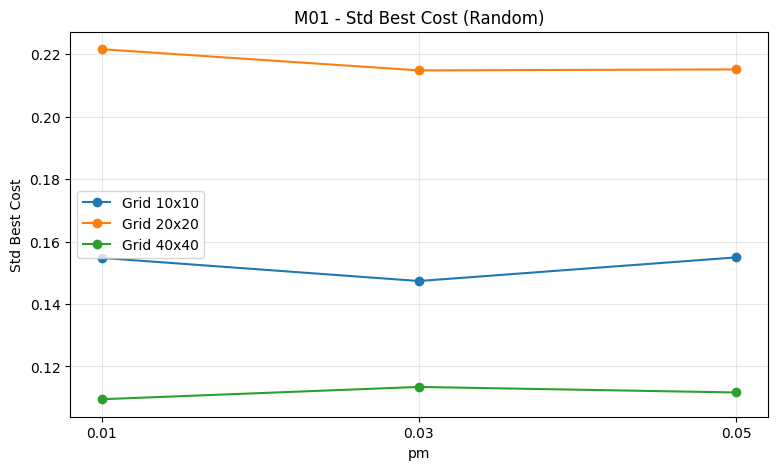

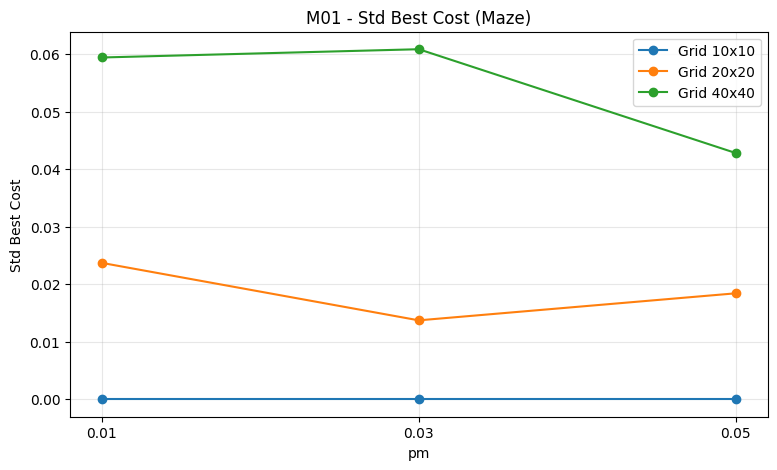

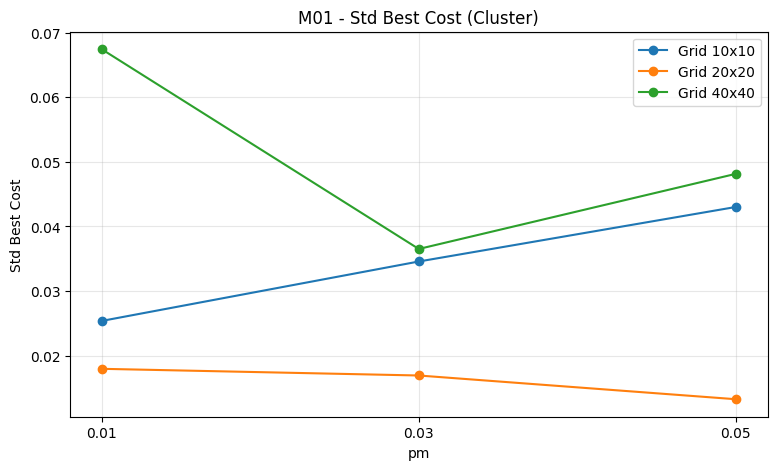

In [16]:
#std cost
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = df_M01_Mutation_summary[
        df_M01_Mutation_summary["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("pm")
        )

        plt.plot(
            data_size["pm"],
            data_size["std_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"M01 - Std Best Cost ({map_type})")
    plt.xlabel("pm")
    plt.ylabel("Std Best Cost")
    plt.xticks(sorted(data["pm"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [17]:
#rank std cost
df_M01_Mutation_summary["rank_std_cost"] = (
    df_M01_Mutation_summary
    .groupby(["grid_rows", "map_type"])["std_cost"]
    .rank(method="average", ascending=True)
)

avg_rank_M01_std = (
    df_M01_Mutation_summary
    .groupby("pm", as_index=False)
    .agg(
        avg_rank_std=("rank_std_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_std_cost", "count")
    )
    .sort_values(["avg_rank_std", "avg_std_cost"])
)

print(avg_rank_M01_std)


     pm  avg_rank_std  avg_std_cost  jumlah_kombinasi
1  0.03      1.777778      0.070908                 9
2  0.05      2.000000      0.071926                 9
0  0.01      2.222222      0.075526                 9


In [24]:
summary_M01_time=(df_M01_Mutation.groupby(["grid_rows","pm", "map_type"], as_index=False).agg(
        mean_execTime=("execution_time_ms", "mean"),
        best_execTime=("execution_time_ms", "min"),
        worst_execTime=("execution_time_ms", "max"),
        std_Time=("execution_time_ms", "std"),
        total_runs=("execution_time_ms", "count")
    ))
display(summary_M01_time)
avg_time_by_population_m01 = (
    summary_M01_time.groupby("pm", as_index=False).agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    ).sort_values("avg_execTime")
)
display(avg_time_by_population_m01)
summary_time_pivot = summary_M01_time.pivot(
    index=["grid_rows", "pm"],
    columns="map_type",
    values="mean_execTime"
)
display(summary_time_pivot)

avg_time_by_map = (
    summary_M01_time.groupby(["map_type", "pm"], as_index=False).agg(
        avg_execTime=("mean_execTime", "mean"),
        avg_std_time=("std_Time", "mean"),
        jumlah_kombinasi=("mean_execTime", "count")
    ).sort_values(["map_type", "avg_execTime"])
)

print(avg_time_by_map)

,grid_rows,pm,map_type,mean_execTime,best_execTime,worst_execTime,std_Time,total_runs
0,10,0.01,Cluster,81.266667,11,465,150.104086,30
1,10,0.01,Maze,85.233333,9,577,173.272097,30
2,10,0.01,Random,85.483333,12,496,148.847492,60
3,10,0.03,Cluster,79.633333,12,482,149.412524,30
4,10,0.03,Maze,79.766667,10,454,147.446234,30
5,10,0.03,Random,87.466667,12,520,151.513882,60
6,10,0.05,Cluster,83.166667,17,431,135.484338,30
7,10,0.05,Maze,82.700000,12,517,161.978319,30
8,10,0.05,Random,87.816667,12,487,141.265646,60
9,20,0.01,Cluster,182.533333,54,731,209.871017,30


,pm,avg_execTime,avg_std_time,jumlah_kombinasi
0,0.01,613.864815,236.386272,9
2,0.05,675.385185,224.697405,9
1,0.03,775.264815,288.887371,9


map_type            Cluster         Maze       Random
grid_rows pm                                         
10        0.01    81.266667    85.233333    85.483333
          0.03    79.633333    79.766667    87.466667
          0.05    83.166667    82.700000    87.816667
20        0.01   182.533333   162.566667   169.850000
          0.03   205.033333   187.233333   199.500000
          0.05   187.400000   189.766667   190.816667
40        0.01  1471.000000  1711.633333  1575.216667
          0.03  1958.466667  2060.066667  2120.216667
          0.05  1690.700000  1540.800000  2025.300000

  map_type    pm  avg_execTime  avg_std_time  jumlah_kombinasi
0  Cluster  0.01    578.266667    261.734034                 3
2  Cluster  0.05    653.755556    230.798781                 3
1  Cluster  0.03    747.711111    259.105542                 3
5     Maze  0.05    604.422222    207.853925                 3
3     Maze  0.01    653.144444    233.764663                 3
4     Maze  0.03    775.688889    293.192224                 3
6   Random  0.01    610.183333    213.660120                 3
8   Random  0.05    767.977778    235.439510                 3
7   Random  0.03    802.394444    314.364348                 3
